# Analyse query execution experiments

Inspect planning and limit-one execution results, then compare experiments across
prompts, models or batch sizes. This notebook only reads saved artifacts: it does
not run queries, call a model or change experiments.

## 1. Setup and selection

Run `uv sync --locked` from the repository root and select the project's `.venv`
Python kernel. Populate `execution_ids` below after rerunning your experiments.
Leave it empty to walk through the notebook without loading data. Only load trusted
pickle artifacts, using compatible BONDI versions.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import yanex.results as yr
from bondi.workload import Workload
from IPython.display import display

from json_storm.analysis import execution_existence_table, execution_planning_table

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 100)

experiments = yr.get_experiments(name="3-exe*", status="completed")
for experiment in experiments:
    if experiment.script_path is None or experiment.script_path.name != "execute.py":
        raise ValueError(f"{experiment.id}: expected an execute.py experiment")
if not experiments:
    print("Add execution IDs above, then Run All. No experiments selected.")

## 2. Load dependencies and native results

Each execution run points to its generation run in the `generate` slot. Query
identity comes from that run's native workload; results are aligned by workload
position. The manifest and version fields help identify incomplete runs or changes
in the codec. Failed experiments remain in the selection.

We recompute classifications with the current helpers from native saved results.
The original `planning.csv`, `existence.csv` and logged metrics remain historical
records and can differ if classification rules change. Missing phases are recorded
as unavailable; their absence must not become a zero failure count.


In [18]:
loaded = {}
context_rows = []
for experiment in experiments:
    generation_id = experiment.dependencies.get("generate")
    if generation_id is None:
        raise ValueError(f"{experiment.id}: missing generate dependency")
    generation = yr.get_experiment(generation_id)
    workload = generation.load_artifact("workload.jsonl", loader=Workload.load)
    if workload is None:
        raise ValueError(f"{generation_id}: missing workload.jsonl")
    manifest = experiment.load_artifact("execution_manifest.json") or {}
    generation_params = generation.get_params()
    execution_params = experiment.get_params()
    phases = {}
    for phase, helper in [
        ("planning", execution_planning_table),
        ("existence", execution_existence_table),
    ]:
        results = experiment.load_artifact(f"{phase}_results.pkl")
        phases[phase] = None if results is None else helper(workload, results)
    loaded[experiment.id] = dict(
        experiment=experiment, generation=generation, workload=workload, phases=phases
    )
    context_rows.append(
        dict(
            experiment_id=experiment.id,
            status=experiment.status,
            generation_id=generation.id,
            prompt_id=generation_params.get("prompt_id"),
            model=generation_params.get("model", {}).get("name"),
            batch_size=generation_params.get("batch_size"),
            workload_size=len(workload),
            timeout_seconds=execution_params.get("mongodb", {}).get("timeout_seconds"),
            concurrency=execution_params.get("mongodb", {}).get("concurrency"),
            versions=manifest.get("versions"),
            completed_phases=manifest.get("completed_phases"),
        )
    )
context = pd.DataFrame(context_rows)
display(context)

,experiment_id,status,generation_id,prompt_id,model,batch_size,workload_size,timeout_seconds,concurrency,versions,completed_phases
0,cdf64528,completed,08c858b4,p1,ollama_chat/qwen3.8:27b-mlx,5,15,60,4,"{'bondi': '0.1.5', 'yanex': '0.6.1'}","[planning, existence]"
1,019a504a,completed,09995930,p2,ollama_chat/qwen3.8:27b-mlx,5,15,60,4,"{'bondi': '0.1.5', 'yanex': '0.6.1'}","[planning, existence]"
2,6ba33452,completed,f2c22b87,p3,ollama_chat/qwen3.8:27b-mlx,5,20,60,4,"{'bondi': '0.1.5', 'yanex': '0.6.1'}","[planning, existence]"
3,fc398c0c,completed,1361a7fc,p4,ollama_chat/qwen3.8:27b-mlx,5,15,60,4,"{'bondi': '0.1.5', 'yanex': '0.6.1'}","[planning, existence]"
4,cfea8073,completed,9178d22d,p5,ollama_chat/qwen3.8:27b-mlx,5,5,60,4,"{'bondi': '0.1.5', 'yanex': '0.6.1'}","[planning, existence]"
5,c0e80b60,completed,e70a53c2,p6,ollama_chat/qwen3.8:27b-mlx,5,20,60,4,"{'bondi': '0.1.5', 'yanex': '0.6.1'}","[planning, existence]"
6,35a3fee8,completed,d7f7d049,p7,ollama_chat/qwen3.8:27b-mlx,5,10,60,4,"{'bondi': '0.1.5', 'yanex': '0.6.1'}","[planning, existence]"


## 3. Inspect one run using both table helpers

Change `selected_id` to inspect another selected run. Planning outcomes are
`passed`, `syntax_error`, `other_error`, `timeout`. Existence outcomes are
`empty`, `nonempty`, `error`, `timeout`.

A passed explain does not guarantee successful execution. An existence timeout
leaves the answer unknown. A nonempty probe establishes one output document,
not successful completion of the original full query.


In [19]:
selected_id = experiments[0].id
selected = loaded.get(selected_id)
planning = selected["phases"]["planning"] if selected else None
existence = selected["phases"]["existence"] if selected else None
for phase, table in [("planning", planning), ("existence", existence)]:
    print(phase)
    if table is None:
        print("No saved results available for this selection.")
    else:
        display(table)
        display(table["outcome"].value_counts().rename("queries").to_frame())

planning


,workload_position,pattern_id,database,collection,query_kind,outcome,elapsed_ms,row_count,error_type,error_code,error_code_name,error_message,warnings
0,0,None,mathexchange,posts,aggregate,other_error,5.549666,None,OperationFailure,40170.0,Location40170,"arguments to $facet must be arrays, highReputationAuthors is type object, full error: {'ok': 0.0...",()
1,1,None,mathexchange,posts,aggregate,passed,5.548292,None,NaN,NaN,NaN,NaN,()
2,2,None,mathexchange,posts,aggregate,syntax_error,6.470084,None,OperationFailure,9.0,FailedToParse,"Unrecognized window function, $subtract, full error: {'ok': 0.0, 'errmsg': 'Unrecognized window ...",()
3,3,None,mathexchange,posts,aggregate,syntax_error,6.860917,None,OperationFailure,9.0,FailedToParse,"Expected a $-prefixed window function, percentRank, full error: {'ok': 0.0, 'errmsg': 'Expected ...",()
4,4,None,mathexchange,posts,aggregate,other_error,0.960333,None,OperationFailure,40234.0,Location40234,"The field 'postCounts' must be an accumulator object, full error: {'ok': 0.0, 'errmsg': ""The fie...",()
5,5,None,mathexchange,posts,aggregate,passed,1.149250,None,NaN,NaN,NaN,NaN,()
6,6,None,mathexchange,posts,aggregate,syntax_error,0.731916,None,OperationFailure,9.0,FailedToParse,"Expected a $-prefixed window function, rank, full error: {'ok': 0.0, 'errmsg': 'Expected a $-pre...",()
7,7,None,mathexchange,posts,aggregate,passed,0.659875,None,NaN,NaN,NaN,NaN,()
8,8,None,mathexchange,posts,aggregate,passed,0.675458,None,NaN,NaN,NaN,NaN,()
9,9,None,mathexchange,posts,aggregate,passed,0.557958,None,NaN,NaN,NaN,NaN,()


,queries
outcome,
passed,8
other_error,4
syntax_error,3


existence


,workload_position,pattern_id,database,collection,query_kind,outcome,elapsed_ms,row_count,error_type,error_code,error_code_name,error_message,warnings
0,0,None,mathexchange,posts,aggregate,error,0.714042,NaN,OperationFailure,40170.0,Location40170,"arguments to $facet must be arrays, highReputationAuthors is type object, full error: {'ok': 0.0...",()
1,1,None,mathexchange,posts,aggregate,timeout,60000.359792,NaN,NetworkTimeout,NaN,NaN,"localhost:27018: timed out (configured timeouts: timeoutMS: 60000.0ms, connectTimeoutMS: 20000.0ms)",()
2,2,None,mathexchange,posts,aggregate,error,0.564834,NaN,OperationFailure,9.0,FailedToParse,"Unrecognized window function, $subtract, full error: {'ok': 0.0, 'errmsg': 'Unrecognized window ...",()
3,3,None,mathexchange,posts,aggregate,error,0.578834,NaN,OperationFailure,9.0,FailedToParse,"Expected a $-prefixed window function, percentRank, full error: {'ok': 0.0, 'errmsg': 'Expected ...",()
4,4,None,mathexchange,posts,aggregate,error,0.527916,NaN,OperationFailure,40234.0,Location40234,"The field 'postCounts' must be an accumulator object, full error: {'ok': 0.0, 'errmsg': ""The fie...",()
5,5,None,mathexchange,posts,aggregate,nonempty,31474.412666,1.0,NaN,NaN,NaN,NaN,()
6,6,None,mathexchange,posts,aggregate,error,0.381750,NaN,OperationFailure,9.0,FailedToParse,"Expected a $-prefixed window function, rank, full error: {'ok': 0.0, 'errmsg': 'Expected a $-pre...",()
7,7,None,mathexchange,posts,aggregate,nonempty,11967.244750,1.0,NaN,NaN,NaN,NaN,()
8,8,None,mathexchange,posts,aggregate,timeout,59999.274500,NaN,ExecutionTimeout,50.0,MaxTimeMSExpired,"PlanExecutor error during aggregation :: caused by :: operation exceeded time limit, full error:...",()
9,9,None,mathexchange,posts,aggregate,nonempty,6607.467041,1.0,NaN,NaN,NaN,NaN,()


,queries
outcome,
error,7
nonempty,6
timeout,2


## 4. Relate planning to execution

Join on `workload_position`, not candidate position: rejected generation candidates
never entered the workload. The cross-tab shows, for example, how many planning
successes became nonempty results versus timeouts.


In [20]:
if planning is not None and existence is not None:
    paired = planning[["workload_position", "outcome"]].merge(
        existence[["workload_position", "outcome", "elapsed_ms"]],
        on="workload_position",
        suffixes=("_planning", "_existence"),
        validate="one_to_one",
    )
    display(paired)
    display(pd.crosstab(paired["outcome_planning"], paired["outcome_existence"]))
else:
    print("Both phase artifacts are needed for the cross-tab.")

,workload_position,outcome_planning,outcome_existence,elapsed_ms
0,0,other_error,error,0.714042
1,1,passed,timeout,60000.359792
2,2,syntax_error,error,0.564834
3,3,syntax_error,error,0.578834
4,4,other_error,error,0.527916
5,5,passed,nonempty,31474.412666
6,6,syntax_error,error,0.381750
7,7,passed,nonempty,11967.244750
8,8,passed,timeout,59999.274500
9,9,passed,nonempty,6607.467041


outcome_existence,error,nonempty,timeout
outcome_planning,,,
other_error,4,0,0
passed,0,6,2
syntax_error,3,0,0


## 5. Inspect errors and the original query

The syntax classification is deliberately narrow. `other_error` can include
unrecognized syntax errors as well as index or permission problems. Inspect the
original error message before attributing failures to the model.

The workload mapping connects execution positions to generation batch/candidate
positions. This also allows us to recover the model's original JSON entry.


In [21]:
if planning is not None:
    errors = planning.loc[planning["outcome"].isin(["syntax_error", "other_error", "timeout"])]
    display(
        errors[
            ["workload_position", "error_type", "error_code", "error_code_name", "error_message"]
        ]
    )
    display(
        errors.groupby(["error_code_name", "error_message"], dropna=False)
        .size()
        .rename("queries")
        .reset_index()
    )

query_position = 0  # zero-based position in the saved workload
if selected and len(selected["workload"]) > query_position:
    display(selected["workload"][query_position].query)
    mapping = selected["generation"].load_artifact("workload_mapping.json")
    if mapping:
        display(pd.DataFrame(mapping).query("workload_position == @query_position"))
else:
    print("Select a nonempty workload to inspect a query.")

,workload_position,error_type,error_code,error_code_name,error_message
0,0,OperationFailure,40170.0,Location40170,"arguments to $facet must be arrays, highReputationAuthors is type object, full error: {'ok': 0.0..."
2,2,OperationFailure,9.0,FailedToParse,"Unrecognized window function, $subtract, full error: {'ok': 0.0, 'errmsg': 'Unrecognized window ..."
3,3,OperationFailure,9.0,FailedToParse,"Expected a $-prefixed window function, percentRank, full error: {'ok': 0.0, 'errmsg': 'Expected ..."
4,4,OperationFailure,40234.0,Location40234,"The field 'postCounts' must be an accumulator object, full error: {'ok': 0.0, 'errmsg': ""The fie..."
6,6,OperationFailure,9.0,FailedToParse,"Expected a $-prefixed window function, rank, full error: {'ok': 0.0, 'errmsg': 'Expected a $-pre..."
11,11,OperationFailure,5371601.0,Location5371601,"Rank style window functions take no other arguments, full error: {'ok': 0.0, 'errmsg': 'Rank sty..."
14,14,OperationFailure,15952.0,Location15952,"unknown group operator '$sample', full error: {'ok': 0.0, 'errmsg': ""unknown group operator '$sa..."


,error_code_name,error_message,queries
0,FailedToParse,"Expected a $-prefixed window function, percentRank, full error: {'ok': 0.0, 'errmsg': 'Expected ...",1
1,FailedToParse,"Expected a $-prefixed window function, rank, full error: {'ok': 0.0, 'errmsg': 'Expected a $-pre...",1
2,FailedToParse,"Unrecognized window function, $subtract, full error: {'ok': 0.0, 'errmsg': 'Unrecognized window ...",1
3,Location15952,"unknown group operator '$sample', full error: {'ok': 0.0, 'errmsg': ""unknown group operator '$sa...",1
4,Location40170,"arguments to $facet must be arrays, highReputationAuthors is type object, full error: {'ok': 0.0...",1
5,Location40234,"The field 'postCounts' must be an accumulator object, full error: {'ok': 0.0, 'errmsg': ""The fie...",1
6,Location5371601,"Rank style window functions take no other arguments, full error: {'ok': 0.0, 'errmsg': 'Rank sty...",1


MongoAggregateQuery(target=MongoCollectionRef(database='mathexchange', collection='posts'), pipeline=[{'$match': {'postTypeId': 1, 'creationDate': {'$gte': datetime.datetime(2023, 1, 1, 0, 0), '$lt': datetime.datetime(2023, 6, 1, 0, 0)}}}, {'$lookup': {'from': 'users', 'localField': 'ownerUserId', 'foreignField': 'userId', 'as': 'owner'}}, {'$lookup': {'from': 'postHistory', 'let': {'currentPostId': '$postId'}, 'pipeline': [{'$match': {'$expr': {'$eq': ['$postId', '$$currentPostId']}}}, {'$match': {'text': {'$exists': True}}}, {'$group': {'_id': None, 'revisionCount': {'$sum': 1}, 'totalChars': {'$sum': {'$concatArrays': [{'$ifNull': [{'$strLenCP': '$text'}, 0]}]}}}}], 'as': 'historyData'}}, {'$unwind': {'path': '$historyData', 'preserveNullAndEmptyArrays': True}}, {'$addFields': {'ownerReputation': {'$ifNull': [{'$arrayElemAt': ['$owner.reputation', 0]}, 0]}, 'hasRevision': {'$cond': {'if': {'$eq': ['$historyData.revisionCount', None]}, 'then': 0, 'else': 1}}}}, {'$setWindowFields': {

,workload_position,batch_index,position
0,0,0,0


## 6. Build a comparison table

One row per execution experiment, preserving each run ID and its configuration.
Counts are computed from the current classification tables, including explicit
zeros for observed phases. Missing phases stay missing. Rates use accepted workload
size as the denominator—not the number originally requested from the model.


In [22]:
outcomes = {
    "planning": ["passed", "syntax_error", "other_error", "timeout"],
    "existence": ["empty", "nonempty", "error", "timeout"],
}
summary_rows = []
for row in context_rows:
    summary = dict(row)
    for phase, labels in outcomes.items():
        table = loaded[row["experiment_id"]]["phases"][phase]
        for label in labels:
            count = None if table is None else int(table["outcome"].eq(label).sum())
            summary[f"{phase}_{label}"] = count
            summary[f"{phase}_{label}_rate"] = (
                count / row["workload_size"] if count is not None and row["workload_size"] else None
            )
    summary_rows.append(summary)
comparison = pd.DataFrame(summary_rows)
if not comparison.empty:
    display(
        comparison[
            [
                "experiment_id",
                "prompt_id",
                "model",
                "batch_size",
                "workload_size",
                "planning_passed",
                "existence_empty",
                "existence_nonempty",
                "existence_error",
                "existence_timeout",
            ]
        ]
    )
else:
    print("Comparison table will populate once execution IDs are provided.")

,experiment_id,prompt_id,model,batch_size,workload_size,planning_passed,existence_empty,existence_nonempty,existence_error,existence_timeout
0,cdf64528,p1,ollama_chat/qwen3.8:27b-mlx,5,15,8,0,6,7,2
1,019a504a,p2,ollama_chat/qwen3.8:27b-mlx,5,15,15,11,4,0,0
2,6ba33452,p3,ollama_chat/qwen3.8:27b-mlx,5,20,19,8,11,1,0
3,fc398c0c,p4,ollama_chat/qwen3.8:27b-mlx,5,15,15,3,12,0,0
4,cfea8073,p5,ollama_chat/qwen3.8:27b-mlx,5,5,4,0,0,2,3
5,c0e80b60,p6,ollama_chat/qwen3.8:27b-mlx,5,20,18,11,7,2,0
6,35a3fee8,p7,ollama_chat/qwen3.8:27b-mlx,5,10,4,0,0,7,3


## 7. Compare outcome distributions visually

Each bar is a run, so repeated model/prompt combinations are kept separate.
Missing phases are omitted from their plot, not rendered as all-zero bars.
For valid nonempty workloads, each bar sums to 100%.


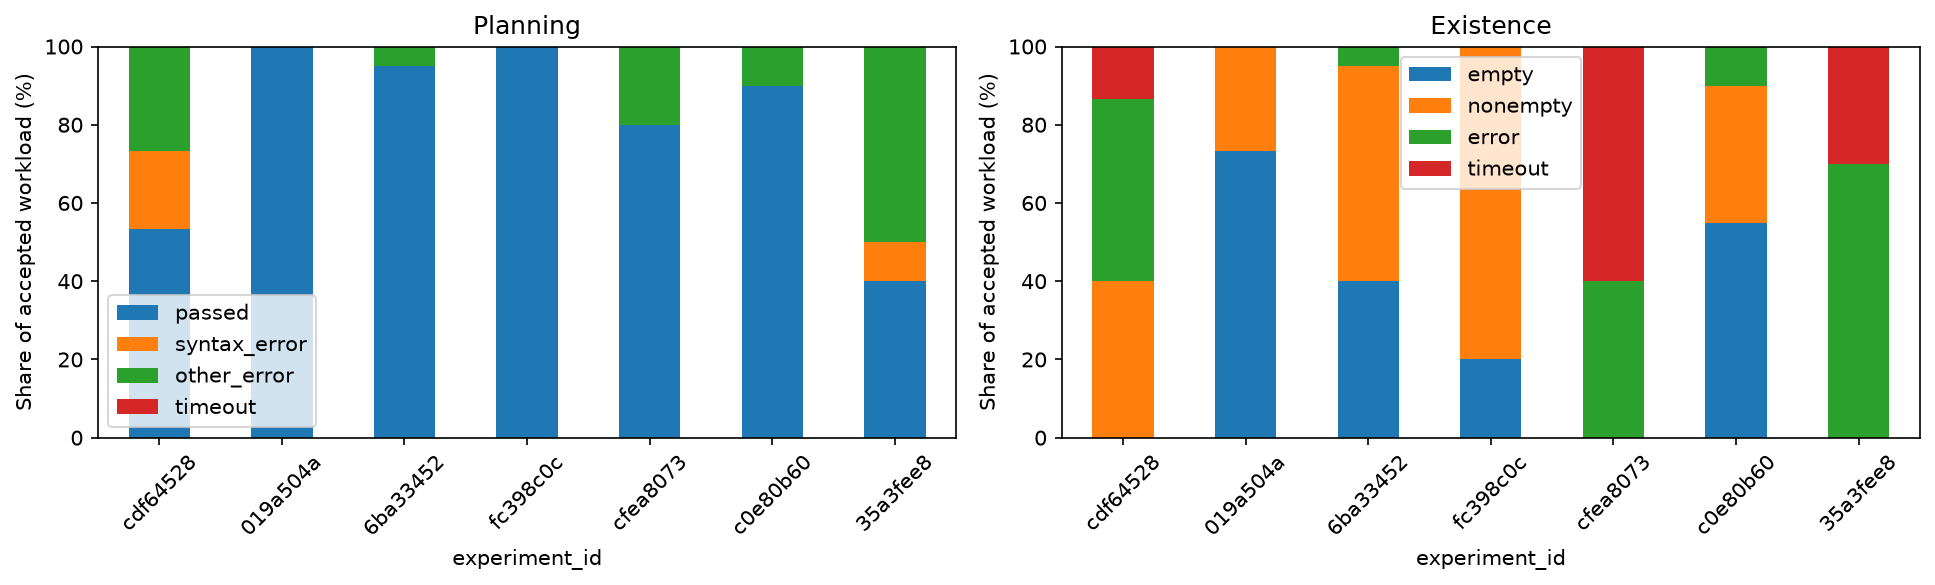

In [23]:
if not comparison.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), dpi=150)
    for ax, (phase, labels) in zip(axes, outcomes.items()):
        columns = [f"{phase}_{label}_rate" for label in labels]
        values = comparison.set_index("experiment_id")[columns].dropna()
        if values.empty:
            ax.text(0.5, 0.5, "No complete phase data", ha="center", transform=ax.transAxes)
        else:
            values = values.rename(columns=dict(zip(columns, labels)))
            (values * 100).plot.bar(stacked=True, ax=ax, rot=45)
        ax.set(title=phase.title(), ylabel="Share of accepted workload (%)", ylim=(0, 100))
    fig.tight_layout()
    plt.show()
else:
    print("No runs to plot.")

## 8. Compare one prompt across models or batch sizes

Filter before comparing. A different timeout, concurrency, dataset/index state or
schema can affect the outcome. Read the configuration table above and use Yanex
dependency lineage to confirm the source schemas. Do not attribute every difference
to model choice. Avoid averaging runs until you have chosen a replicate strategy.


In [24]:
selected_prompt = "p1"
if not comparison.empty:
    prompt_runs = comparison.loc[comparison["prompt_id"].eq(selected_prompt)]
    display(
        prompt_runs[
            [
                "experiment_id",
                "model",
                "batch_size",
                "timeout_seconds",
                "concurrency",
                "workload_size",
                "existence_nonempty_rate",
                "existence_empty_rate",
                "existence_timeout_rate",
            ]
        ].sort_values(["model", "batch_size"])
    )
else:
    print("Add run IDs to compare a prompt across configurations.")

,experiment_id,model,batch_size,timeout_seconds,concurrency,workload_size,existence_nonempty_rate,existence_empty_rate,existence_timeout_rate
0,cdf64528,ollama_chat/qwen3.8:27b-mlx,5,60,4,15,0.4,0.0,0.133333


## Interpretation checklist

- Generated-query acceptance and executable-query yield use different denominators.
- Empty means no output documents; a document containing a zero count is nonempty.
- Timeouts and errors must remain separate from empty results.
- Limit-one latency is not full-query runtime; blocking sorts/groups may still do substantial work.
- Older artifacts can reflect older parser/codec bugs; compare recorded BONDI versions.
- Raw native results remain available in `planning_results.pkl` and `existence_results.pkl`.
- Saved CSVs and logged metrics describe the original analysis; rerunning these helpers
  applies the current classification rules without changing those historical records.
